# Laboratorium 1: regresja liniowa i kwartet Anscombe’a

Kompletne rozwiązania trzech zadań. Dane wejściowe są lokalne, a wzory i funkcje obliczeniowe znajdują się w [analysis.py](analysis.py). Sprawozdanie w LaTeX-u jest w katalogu `report/`.

Wybierz kernel z projektowego `.venv`, a następnie uruchom wszystkie komórki. W głównych tabelach wariancja ma dzielnik **n − 1**. Osobno pokazujemy również wariancję z dzielnikiem **n**.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()
)
LAB_DIR = PROJECT_ROOT / "labs" / "lab01"
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

In [2]:
from analysis import (
    IMAGE_DIR,
    OUTPUT_DIR,
    configure_plots,
    detect_outliers,
    export_formats,
    fit_ols,
    load_anscombe,
    load_task3,
    plot_anscombe,
    plot_outliers,
    plot_task3,
    summarize,
)

configure_plots()
pd.options.display.float_format = "{:.6f}".format

## Zadanie 1: średnie, wariancje, korelacje i regresja

Dla każdej serii dopasowujemy $\hat y = \hat\beta_1 x + \hat\beta_0$, gdzie

$$\hat\beta_1 = \frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2}, \qquad \hat\beta_0=\bar y-\hat\beta_1\bar x.$$

Funkcja `fit_ols` oblicza te wzory bezpośrednio. Testy porównują wynik z niezależnym rozwiązaniem `numpy.linalg.lstsq` i funkcjami SciPy.

In [3]:
quartet = load_anscombe()
statistics = summarize(quartet)
display(quartet.head())
display(
    statistics[["series", "n", "mean_x", "mean_y", "var_x_sample", "var_y_sample", "pearson_r"]]
)
display(
    statistics[
        ["series", "var_x_population", "var_y_population", "beta0", "beta1", "r_squared", "rmse"]
    ]
)

,series,x,y
0,I,10.000000,8.040000
1,I,8.000000,6.950000
2,I,13.000000,7.580000
3,I,9.000000,8.810000
4,I,11.000000,8.330000


,series,n,mean_x,mean_y,var_x_sample,var_y_sample,pearson_r
0,I,11,9.000000,7.500909,11.000000,4.127269,0.816421
1,II,11,9.000000,7.500909,11.000000,4.127629,0.816237
2,III,11,9.000000,7.500000,11.000000,4.122620,0.816287
3,IV,11,9.000000,7.500909,11.000000,4.123249,0.816521


,series,var_x_population,var_y_population,beta0,beta1,r_squared,rmse
0,I,10.000000,3.752063,3.000091,0.500091,0.666542,1.118550
1,II,10.000000,3.752390,3.000909,0.500000,0.666242,1.119102
2,III,10.000000,3.747836,3.002455,0.499727,0.666324,1.118286
3,IV,10.000000,3.748408,3.001727,0.499909,0.666707,1.117729


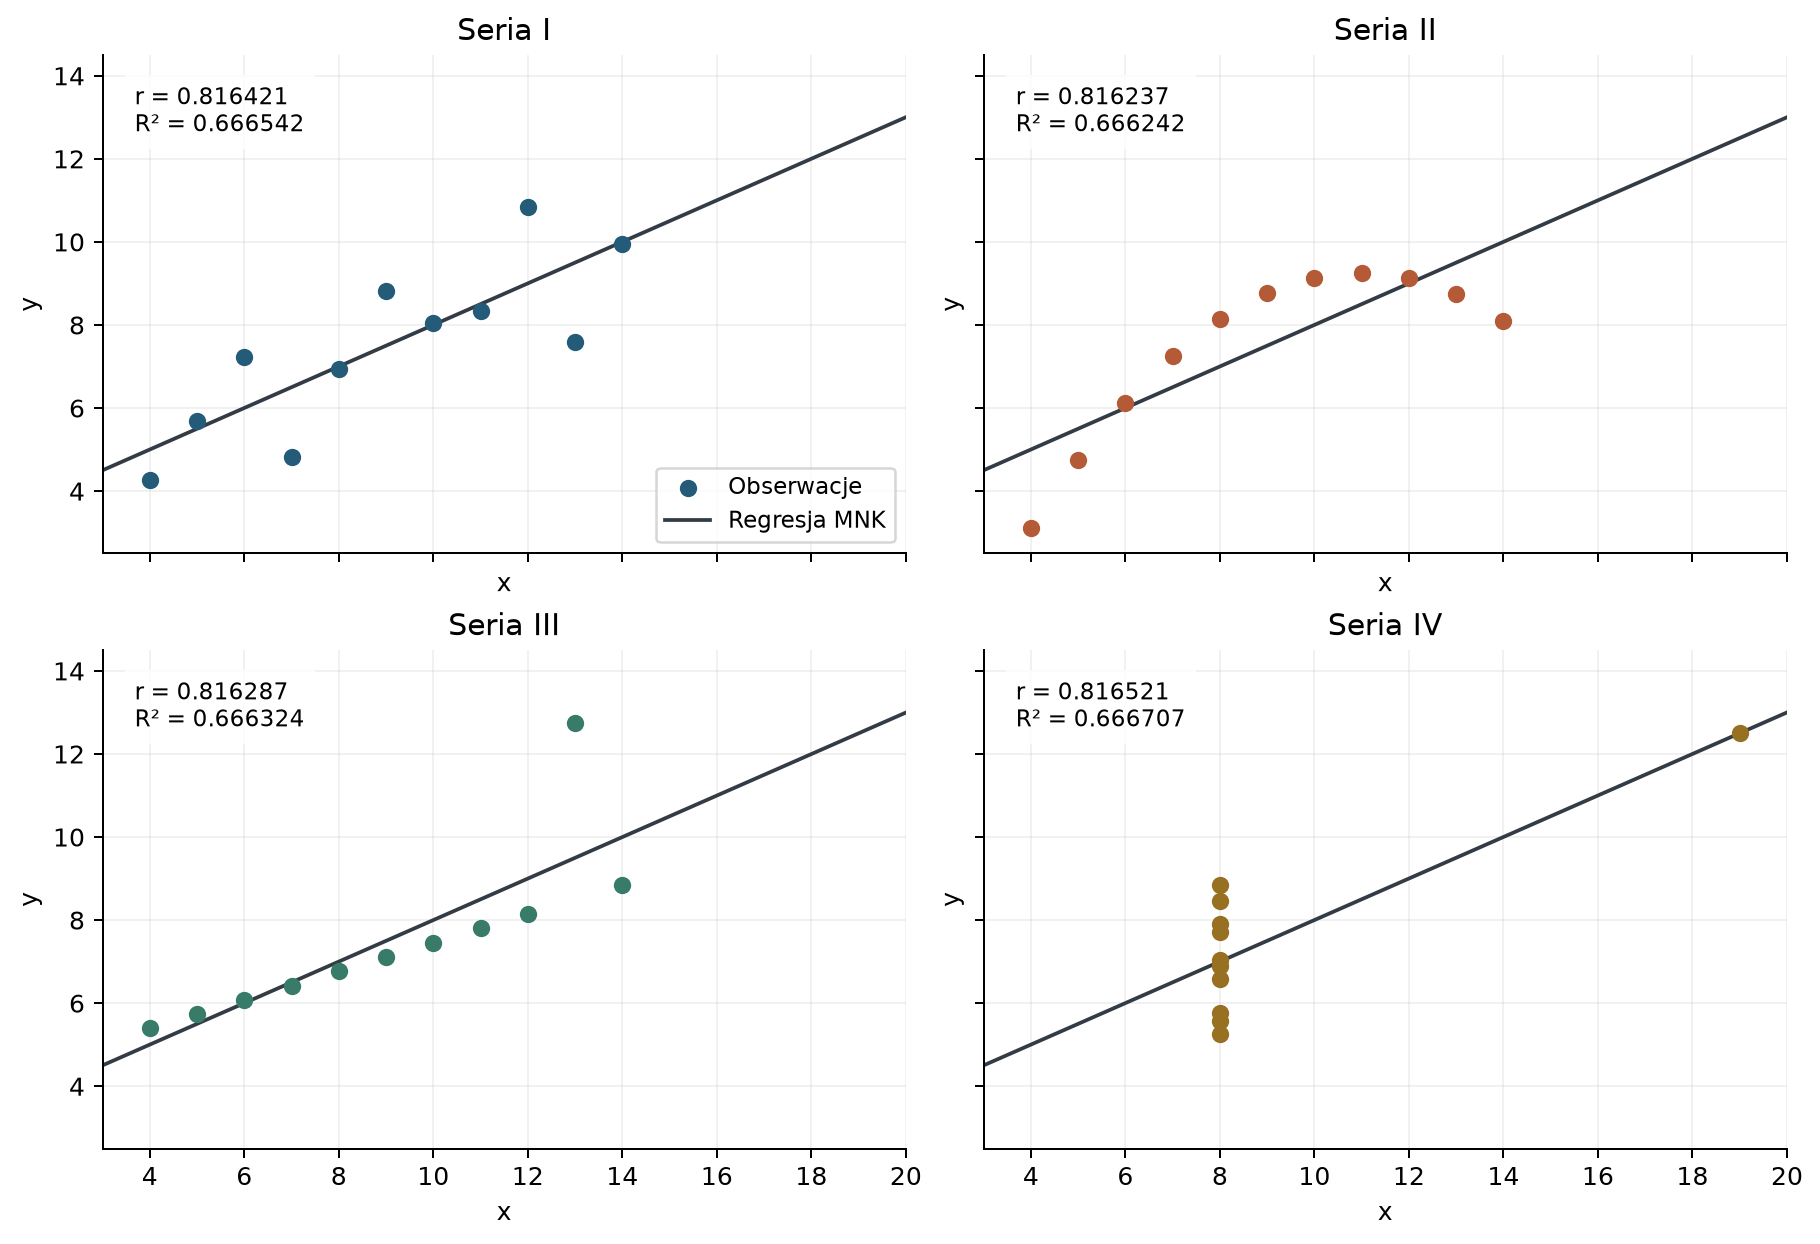

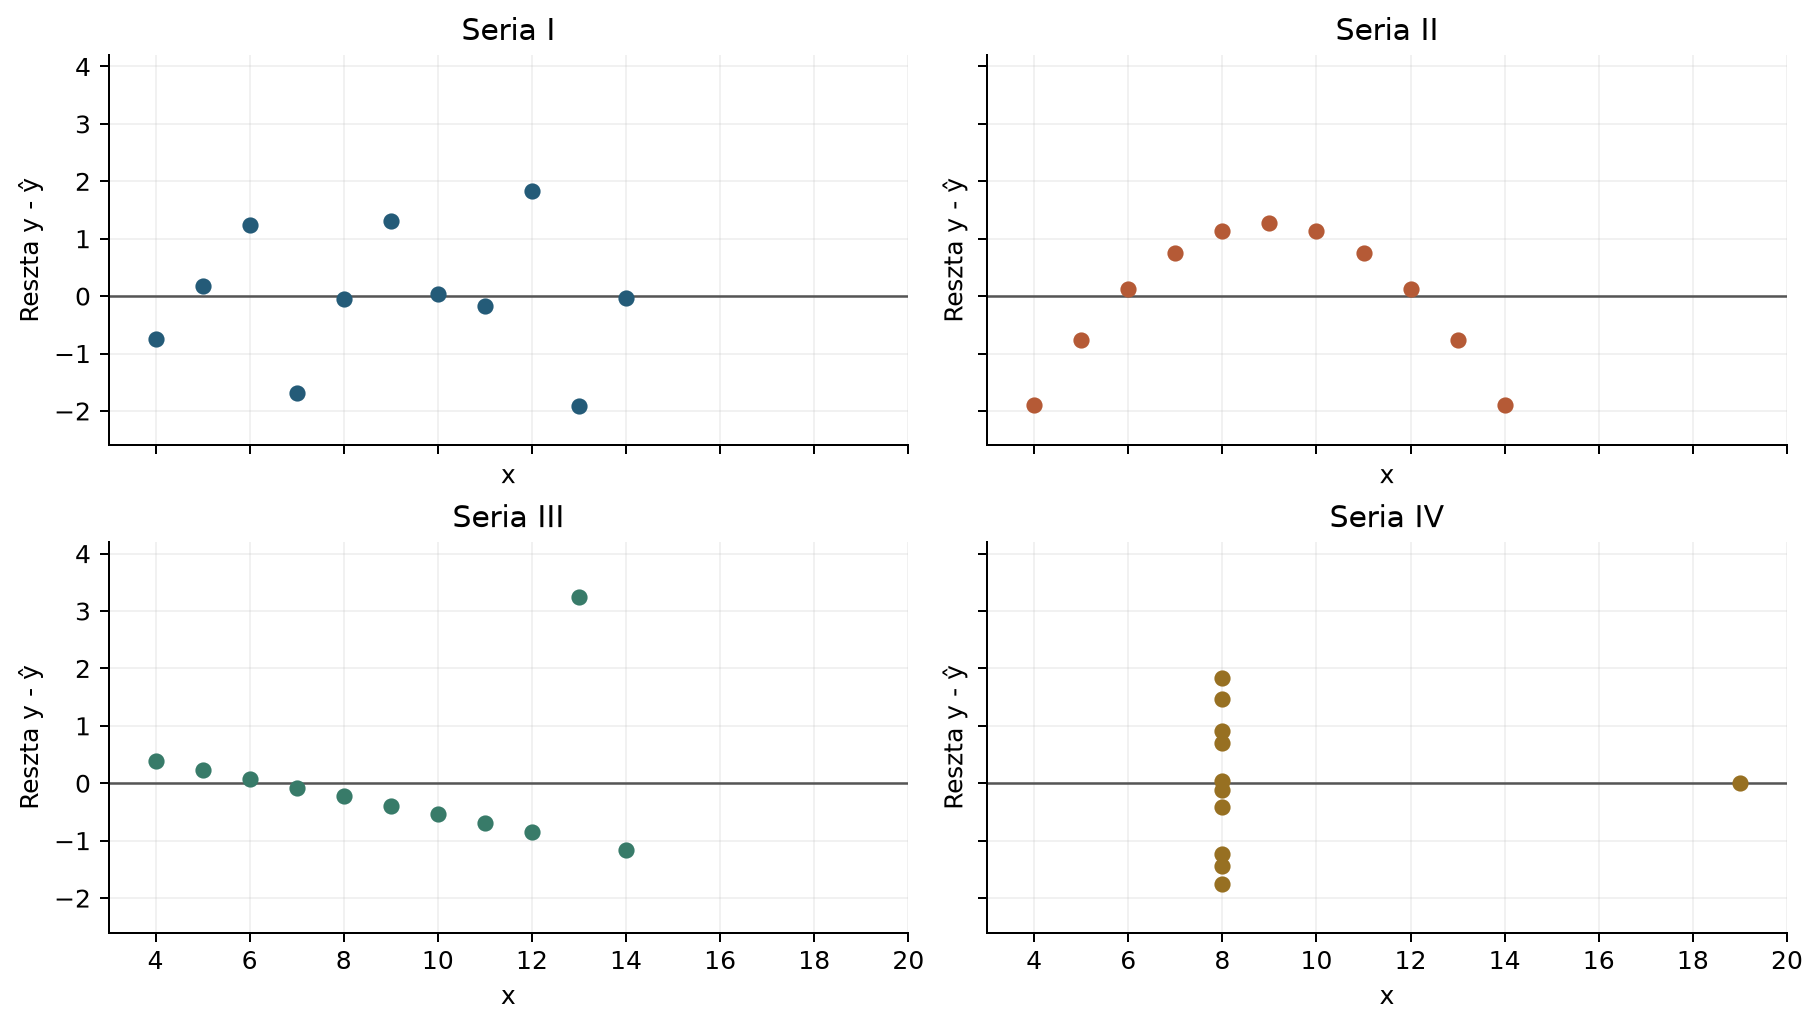

In [4]:
plot_anscombe(quartet)
display(Image(filename=str(IMAGE_DIR / "anscombe_regression.png"), width=1000))
display(Image(filename=str(IMAGE_DIR / "anscombe_residuals.png"), width=1000))

### Wnioski z zadania 1

1. Każda seria ma średnią x równą 9 i wariancję z próby x równą 11, ale odmienne rozmieszczenie punktów.
2. Zbliżone statystyki i proste około y = 0,5x + 3 nie wystarczają do rozpoznania struktury danych.
3. Seria II jest zakrzywiona; systematyczny łuk reszt wskazuje ograniczenie modelu liniowego.
4. W serii III pojedynczy punkt wpływa na parametry MNK i zasłania prawie idealną zależność pozostałych obserwacji.
5. W serii IV dziesięć punktów ma x = 8. Po usunięciu jedynego punktu z x = 19 nachylenie nie jest identyfikowalne.
6. Wariancja opisowa x wynosi 10. Różnica względem 11 wynika z dzielnika, a nie z błędu obliczeń.

Niezależne obliczenia w arkuszu i cztery edytowalne wykresy są w `outputs/anscombe.xlsx`.

## Zadanie 2: CSV, JSON i XML

Przyjmujemy, że „dane z poprzedniego laboratorium” oznaczają kwartet z zadania 1. Zapisujemy identyczne 44 rekordy w UTF-8 bez BOM. Rozmiary dotyczą rzeczywistych bajtów przed kompresją.

In [5]:
format_sizes = export_formats(quartet)
display(format_sizes)
first_json_record = json.loads((OUTPUT_DIR / "anscombe.json").read_text(encoding="utf-8"))[0]
print(json.dumps([first_json_record], ensure_ascii=False, indent=2))

,file,bytes,relative_to_csv
0,anscombe.csv,555,1.000000
1,anscombe.json,1470,2.648649
2,anscombe_pretty.json,2527,4.553153
3,anscombe.xml,3033,5.464865
4,anscombe_pretty.xml,3958,7.131532


[
  {
    "series": "I",
    "x": 10.0,
    "y": 8.04
  }
]


### JSON i porównanie formatów

JSON przechowuje tutaj tablicę obiektów z kluczami `series`, `x` i `y`. Napisy i klucze wymagają podwójnych cudzysłowów, a liczby są zapisywane bez cudzysłowów. Obiekty używają `{}`, tablice `[]`. Dozwolone są także `true`, `false` i `null`. Ścisły JSON nie dopuszcza komentarzy, końcowych przecinków, `NaN` i nieskończoności. Jest często stosowany w API internetowych i do wymiany zagnieżdżonych danych. Źródło: [RFC 8259](https://www.rfc-editor.org/rfc/rfc8259).

1. CSV jest najmniejszy dla tej płaskiej tabeli: 555 B.
2. Zwarty JSON ma 1470 B, a zwarty XML 3033 B; nazwy pól i znaczniki zwiększają narzut.
3. Wcięcia powiększają oba formaty bez zmiany zawartości danych.
4. Rozmiar zależy od konkretnego schematu i ustawień zapisu, więc nie jest uniwersalną własnością formatu.
5. Kontrolny odczyt wszystkich formatów zachowuje rekordy, wartości i kolejność.

### Obserwacja odstająca w serii III

Najpierw dopasowujemy odporną prostą Theila–Sena. Następnie oceniamy bezwzględne odchylenie reszt od ich mediany w jednostkach normalizowanego MAD. Flaga oznacza wynik powyżej 3,5. Znana rozdzielczość y = 0,01 zapewnia dolne ograniczenie skali $0{,}01/\sqrt{12}$, aby zaokrąglenia przy niemal dokładnej prostej nie powodowały dzielenia przez zero.

Regułę ustalamy przed porównaniem R². Dane oryginalne pozostają bez zmian, a po filtrowaniu dopasowujemy ponownie zwykłą MNK.

,x,y,robust_residual,robust_score,is_outlier
22,10.000000,7.460000,0.004444,0.000000,False
23,8.000000,6.770000,0.005556,0.337245,False
24,13.000000,12.740000,4.247778,1287.938178,True
25,9.000000,7.110000,0.000000,1.348980,False
26,11.000000,7.810000,0.008889,1.348980,False
27,14.000000,8.840000,0.002222,0.674490,False
28,6.000000,6.080000,0.006667,0.674490,False
29,4.000000,5.390000,0.007778,1.011735,False
30,12.000000,8.150000,0.003333,0.337245,False
31,7.000000,6.420000,0.001111,1.011735,False


,data,n,beta0,beta1,r_squared,rmse
0,Przed,11,3.002455,0.499727,0.666324,1.118286
1,Po,10,4.005649,0.345390,0.999993,0.002756


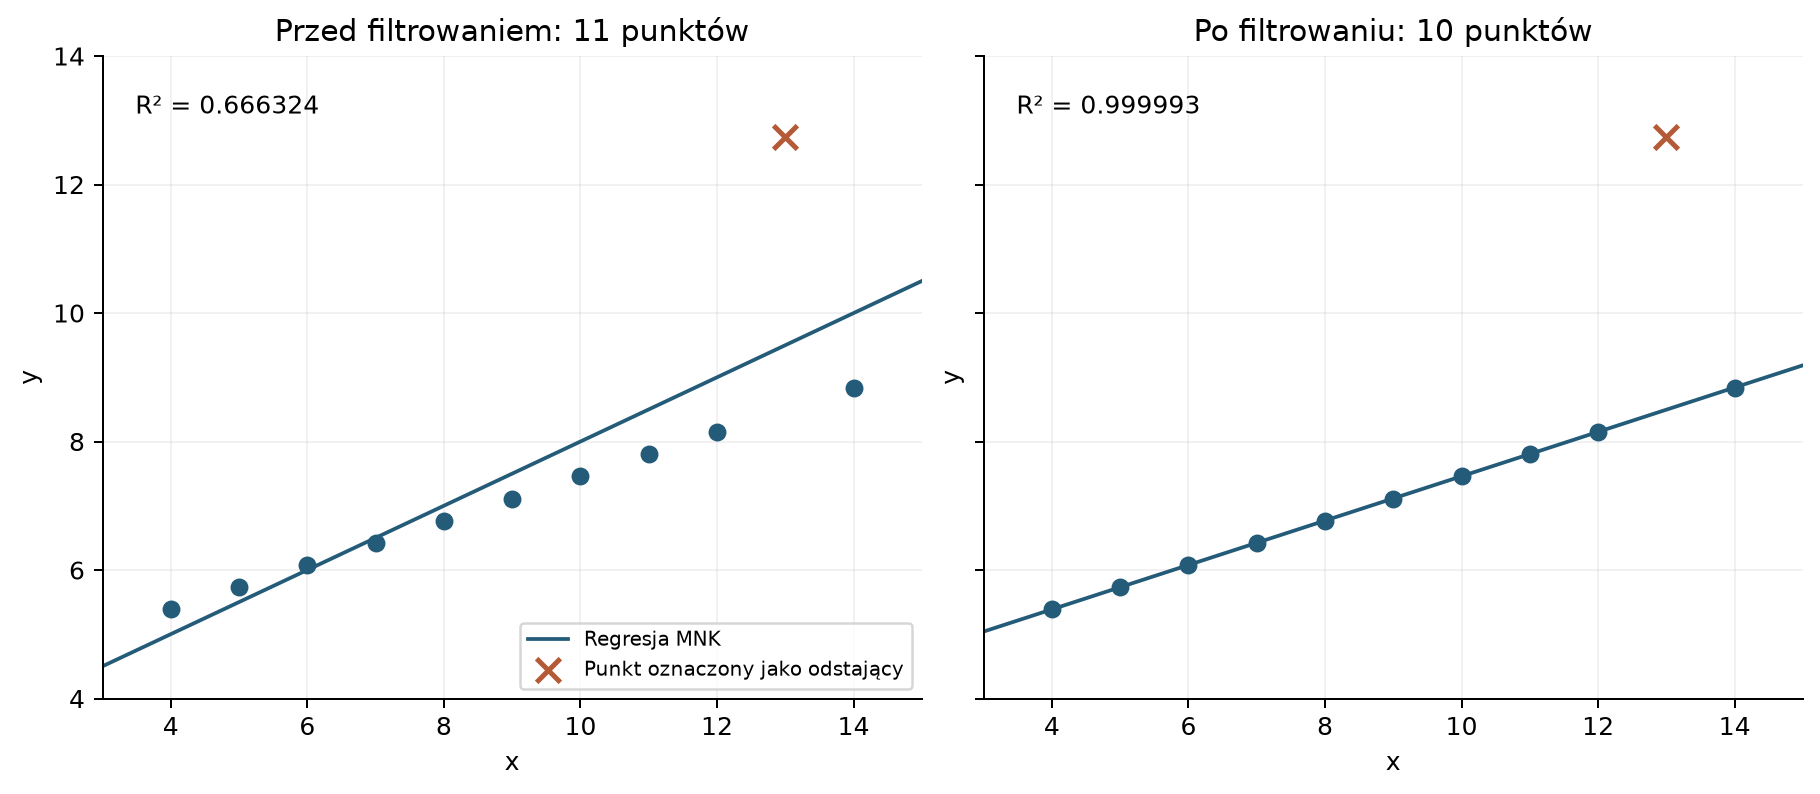

In [6]:
third_series = quartet.loc[quartet.series == "III"]
diagnostics = detect_outliers(third_series)
retained = diagnostics.loc[~diagnostics.is_outlier]
comparison = pd.DataFrame(
    [
        {"data": "Przed", **fit_ols(diagnostics.x.to_numpy(), diagnostics.y.to_numpy())},
        {"data": "Po", **fit_ols(retained.x.to_numpy(), retained.y.to_numpy())},
    ]
)
display(diagnostics[["x", "y", "robust_residual", "robust_score", "is_outlier"]])
display(comparison[["data", "n", "beta0", "beta1", "r_squared", "rmse"]])
plot_outliers(diagnostics)
display(Image(filename=str(IMAGE_DIR / "outlier_comparison.png"), width=1000))

### Wnioski dotyczące filtrowania

1. Oznaczony jest dokładnie punkt (13; 12,74), a próg nie jest dopasowywany w celu maksymalizacji R².
2. R² wzrasta z około 0,666324 do 0,999993, a nachylenie maleje z około 0,499727 do 0,345390.
3. RMSE spada z około 1,118286 do 0,002756. Pozostałe punkty są niemal współliniowe.
4. Próg 3, 3,5 lub 4 daje tę samą wskazaną obserwację; wynik jest stabilny na taką zmianę.
5. Wskaźniki przed i po dotyczą różnych prób. Wzrost R² nie jest oceną jakości predykcji na nowych danych.
6. Sam odstający wynik nie dowodzi błędu pomiaru. Należy zachować oryginał, udokumentować regułę i porównać oba modele.

## Zadanie 3: seria 1 oraz dwie inne serie

Pełny CSV odtworzono z obrazu `data/data_zad3.png`: 13 serii po 142 obserwacje. Wszystkie liczby porównano z publicznym zbiorem autorów; informacje o źródle i sumach kontrolnych są w `data/provenance.json`.

Wybieramy serię 1 i serie 9 oraz 10. Ich kształty to odpowiednio dinozaur, owalny pierścień i tarcza. Zachowujemy jednakowe zakresy i proporcje osi.

,series,n,mean_x,mean_y,var_x_sample,var_y_sample,pearson_r
0,seria1,142,54.263273,47.832253,281.069988,725.515961,-0.064472
1,seria9,142,54.267320,47.837717,280.898024,725.226844,-0.068343
2,seria10,142,54.268730,47.830823,281.207393,725.533372,-0.068586


,series,beta0,beta1,r_squared,rmse
0,seria1,53.452978,-0.103583,0.004157,26.784552
1,seria9,53.797045,-0.109814,0.004671,26.772300
2,seria10,53.809471,-0.110167,0.004704,26.777510


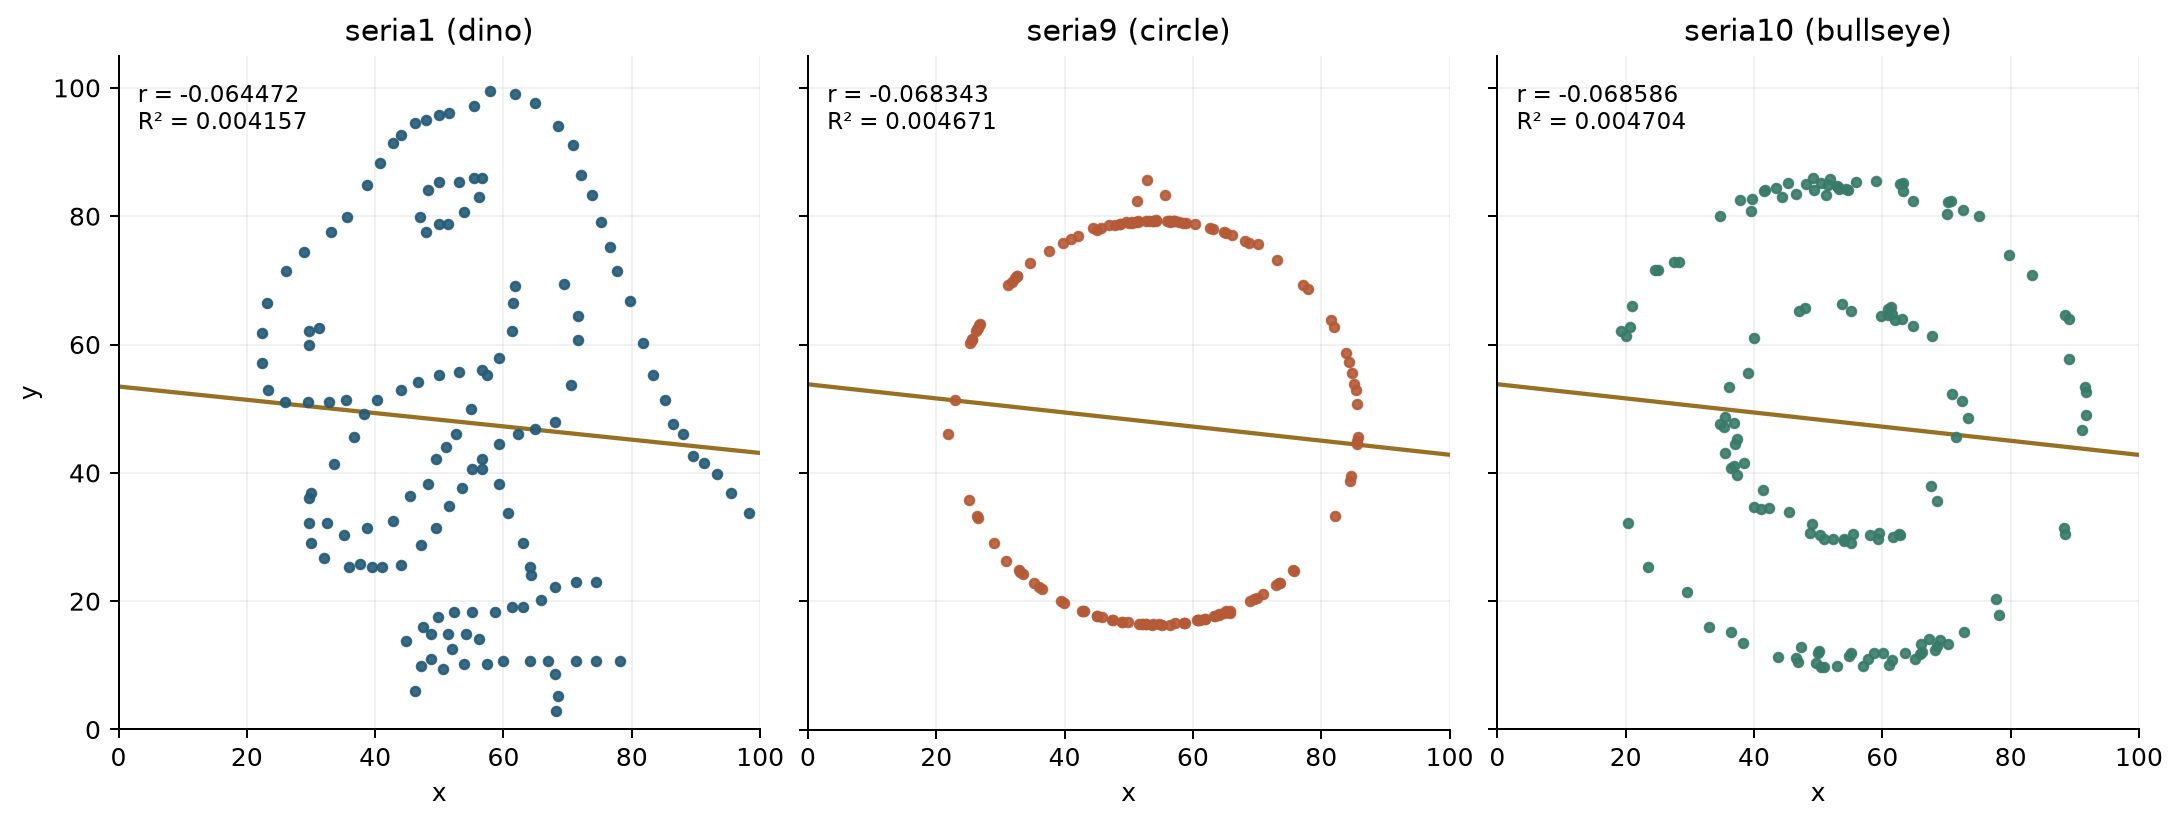

In [7]:
task3_data = load_task3()
selected_names = ["seria1", "seria9", "seria10"]
selected_data = task3_data.loc[task3_data.series.isin(selected_names)]
task3_statistics = summarize(selected_data)
display(
    task3_statistics[
        ["series", "n", "mean_x", "mean_y", "var_x_sample", "var_y_sample", "pearson_r"]
    ]
)
display(task3_statistics[["series", "beta0", "beta1", "r_squared", "rmse"]])
plot_task3(task3_data)
display(Image(filename=str(IMAGE_DIR / "task3_regression.png"), width=1200))

### Wnioski z zadania 3

1. Wszystkie wybrane serie mają zbliżone średnie x ≈ 54,26 i y ≈ 47,83 oraz podobne wariancje, mimo różnych kształtów.
2. Korelacja od −0,064 do −0,069 opisuje bardzo słabą zależność liniową. Nie oznacza braku struktury geometrycznej.
3. Każda prosta ma R² poniżej 0,005 i wyjaśnia mniej niż 0,5% zmienności y.
4. Serie 9 i 10 mają szczególnie podobne proste, lecz różnią się układem pierścieni i skupień.
5. Wykresy pokazują informacje utracone przy redukcji danych do pojedynczych statystyk.
6. Równe skale i proporcje osi są konieczne do uczciwego porównania kształtów.

## Sprawozdanie i oddanie

Pełne sprawozdanie zawiera 33 numerowane wnioski. Aby odtworzyć tabele i rysunki raportu, uruchom z głównego katalogu `uv run python labs/lab01/analysis.py`. Polecenie `uv run python labs/lab01/package_submission.py` kompiluje PDF i przygotowuje paczki do Overleafa i ePortalu. Dane autorów są przechowywane lokalnie, poza Gitem.